In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

tune_path = [
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-140414_slim.pt",#wrong
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-163208_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-190205_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-165010_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-174312_slim.pt",
]

tune_files = ["../" + i for i in tune_path]

vae_path = [
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-140404_slim.pt",#wrong
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-145858_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-155505_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-165010_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-174312_slim.pt"
]
vae_files = ["../" + i for i in vae_path]

range_path = [
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-140454_slim.pt", #wrong
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-163353_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-190344_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261116-213216_slim.pt",
    "artifacts/eval/eval_results_checkpoint_epochbest_20261117-000406_slim.pt"
]

range_files = ["../" + i for i in range_path]



def get_json(path):
    try:
        with open(path, "r") as f:
            return json.load(f)
    except Exception as e:
        print(path, e)
        return None

In [2]:


data_tune = []
for t in tune_files:
    data_tune.append(get_json(t))

data_vae = []
for t in vae_files:
    data_vae.append(get_json(t))


data_range = []
for t in range_files:
    data_range.append(get_json(t))


print(data_range[0].keys())

dict_keys(['ratio', 'mutual_info', 'density_missmatch', 'layered_first_step', 'posterior_losses_position', 'loss_posterior', 'mse_loss_posterior', 'layered_kl', 'layer_target', 'layer_residual', 'lambda', 'lambda_lower', 'lambda_upper', 'layer_budget_weights', 'losses', 'losses_position', 'loss', 'loss_position', 'mse_loss', 'mse_losses', 'mse_losses_position', 'mse_loss_position', 'scrambled_loss', 'checkpoint_path'])


In [3]:
def object_to_dataframe(data, rnn=False):
    if data is None:
        return None
    
    to_return = {}
    to_return["x"] = data["x"]
    to_return["mean"] = data["mean"]
    to_return["logvar"] = data["logvar"]
    to_return["losses"] = data["losses"]    
    to_return["losses_position"] = data["losses_position"]
    to_return["mse_losses"] = data["mse_losses"]
    to_return["mse_losses_position"] = data["mse_losses_position"]
    to_return["mse_loss"] = data["mse_loss"]

    return pd.DataFrame.from_dict(to_return)


def multiple_objects_to_dataframe(data):
    to_return = []
    for d in data:
        to_return.append(object_to_dataframe(d))
    return pd.concat(to_return)

dict_keys(['ratio', 'mutual_info', 'density_missmatch', 'layered_first_step', 'posterior_losses_position', 'loss_posterior', 'mse_loss_posterior', 'layered_kl', 'layer_target', 'layer_residual', 'lambda', 'lambda_lower', 'lambda_upper', 'layer_budget_weights', 'losses', 'losses_position', 'loss', 'loss_position', 'mse_loss', 'mse_losses', 'mse_losses_position', 'mse_loss_position', 'scrambled_loss', 'checkpoint_path'])
[1.3294024467468262, 1.3290951251983643, 1.3355284929275513, 1.332392692565918, 1.3221526145935059, 1.340611457824707, 1.3469747304916382, 1.3599485158920288, 1.3625534772872925, 1.3745542764663696, 1.3801395893096924, 1.3893916606903076, 1.389880895614624, 1.4034850597381592, 1.4076011180877686, 1.401719331741333, 1.397329568862915, 1.384494662284851, 1.3756458759307861, 1.4054512977600098, 1.5077117681503296, 1.5066015720367432, 1.5059162378311157, 1.5346671342849731, 1.5747190713882446, 1.5702598094940186, 1.596556544303894, 1.6031625270843506, 1.6187541484832764, 1.6

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'VAE Ratio per seed'}>)

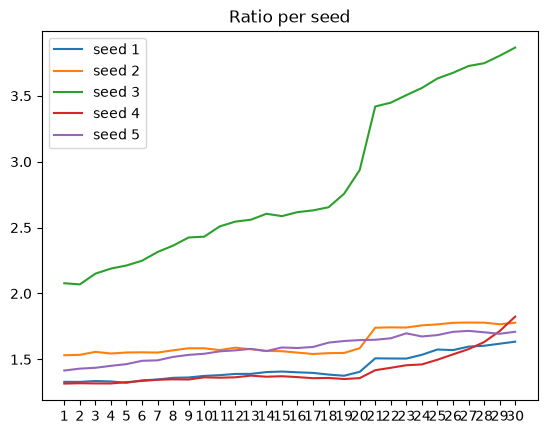

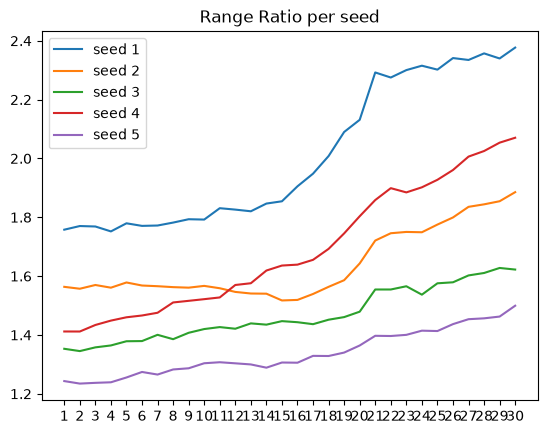

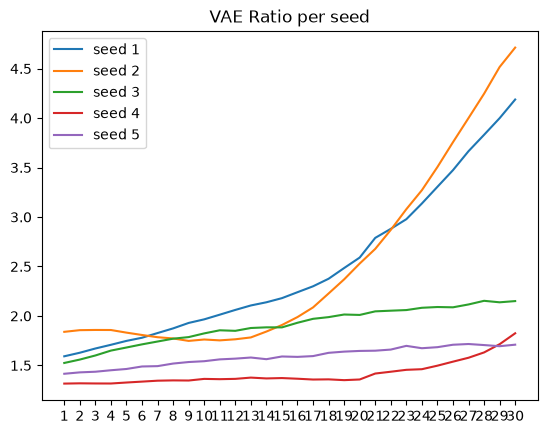

In [4]:

print(data_tune[0].keys())

def basic_plot(models, title, labels):
    fig, ax = plt.subplots()

    for m, label in zip(models, labels):
        try:
            data = np.array(m)
    
            
            x = np.arange(1, data.shape[0] + 1)
    
            ax.plot(x, data, label=label)
        except:
            print(":(")
        

    ax.set_xticks(x)
    ax.set_title(title)
    ax.legend()

    return fig, ax


print(data_tune[0]["ratio"])
basic_plot(models=[d["ratio"] for d in data_tune],
           title="Ratio per seed",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["ratio"] for d in data_range],
           title="Range Ratio per seed",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["ratio"] for d in data_vae],
           title="VAE Ratio per seed",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])




(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Posterior loss Range'}>)

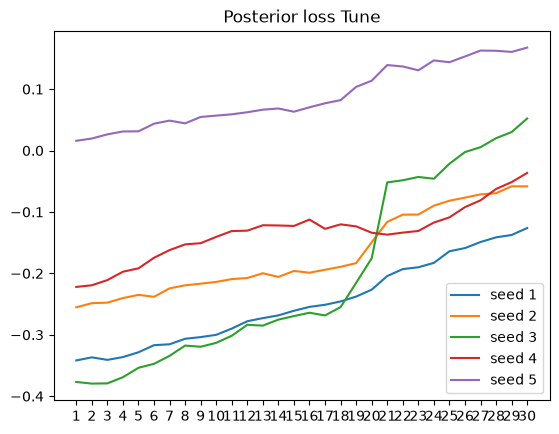

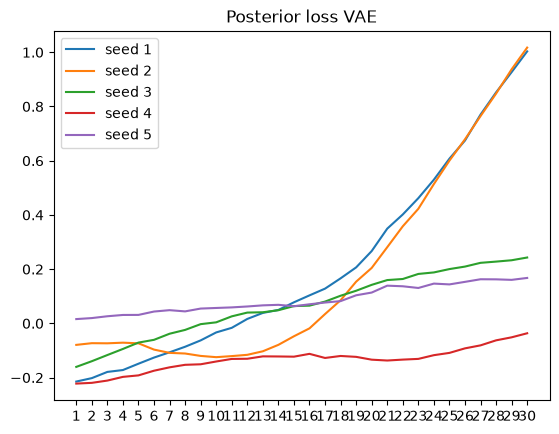

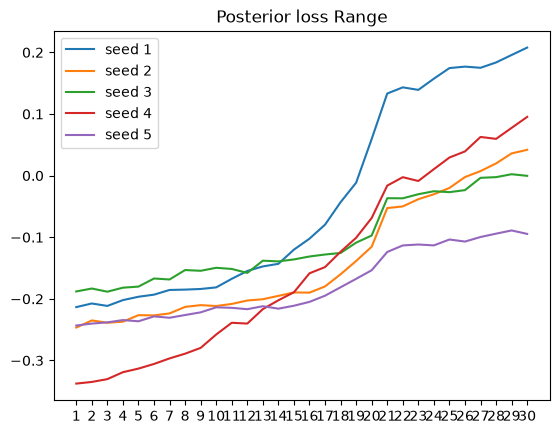

In [5]:



basic_plot(models=[d["posterior_losses_position"] for d in data_tune],
           title="Posterior loss Tune",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["posterior_losses_position"] for d in data_vae],
           title="Posterior loss VAE",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["posterior_losses_position"] for d in data_range],
           title="Posterior loss Range",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])




(<Figure size 640x480 with 1 Axes>, <Axes: title={'center': 'NLL Range'}>)

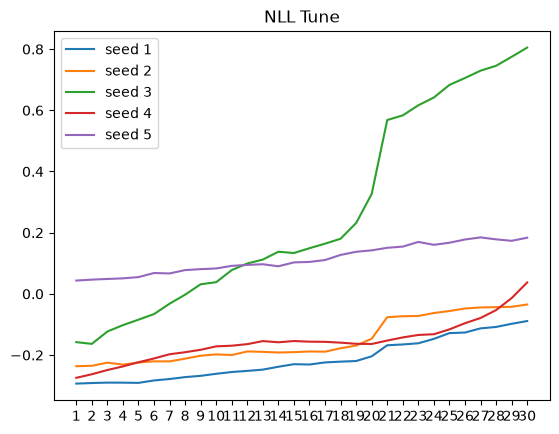

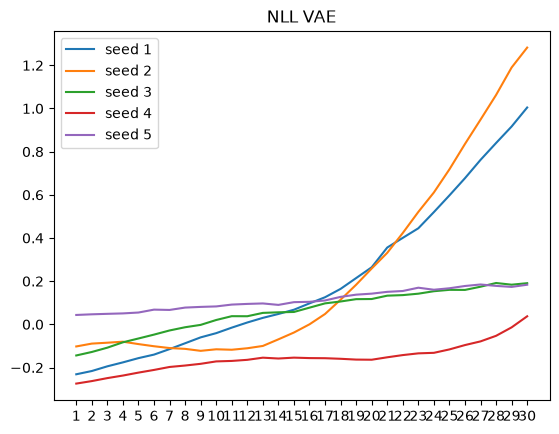

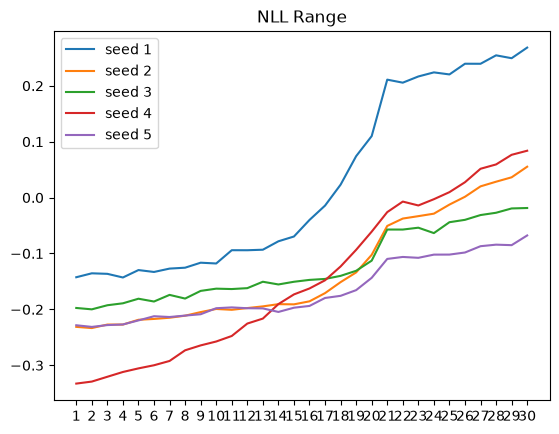

In [6]:




basic_plot(models=[d["losses_position"] for d in data_tune],
           title="NLL Tune",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["losses_position"] for d in data_vae],
           title="NLL VAE",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])

basic_plot(models=[d["losses_position"] for d in data_range],
           title="NLL Range",
           labels=["seed %i" % i for i in range(1, len(data_tune) + 1)])



(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Mean NLL per position'}>)

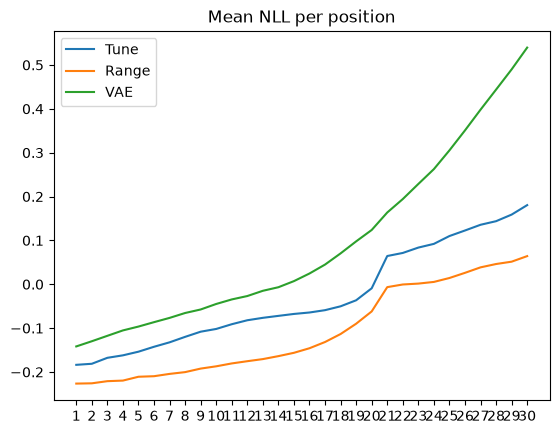

In [7]:
def mean_plot(models, title, labels):
    fig, ax = plt.subplots()

    for m, label in zip(models, labels):
        
        data = np.stack([np.array(i) for i in m],axis=0).mean(axis=0)

        
        x = np.arange(1, data.shape[0] + 1)

        ax.plot(x, data, label=label)
        

    ax.set_xticks(x)
    ax.set_title(title)
    ax.legend()

    return fig, ax


t = [d["losses_position"] for d in data_tune]
r = [d["losses_position"] for d in data_range]
v = [d["losses_position"] for d in data_vae]


mean_plot(models = [t,r,v],
          title="Mean NLL per position",
          labels=["Tune", "Range", "VAE"])

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Mean RATIO per position'}>)

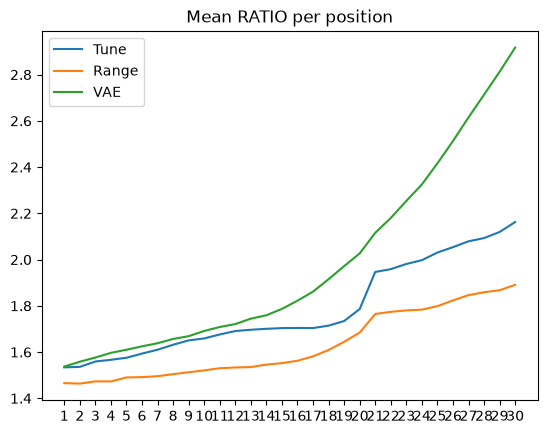

In [8]:
t = [d["ratio"] for d in data_tune]
r = [d["ratio"] for d in data_range]
v = [d["ratio"] for d in data_vae]


mean_plot(models = [t,r,v],
          title="Mean RATIO per position",
          labels=["Tune", "Range", "VAE"])